# Buổi D2: Đọc bệnh của mô hình bằng đường cong

**Hiện trường.** Chị Hạnh có một mô hình chữ số viết tay đúng 100% trên bài cũ nhưng thấp hơn nhiều trên đề mới. Đồng nghiệp bảo *"thu thêm dữ liệu đi"*, người khác bảo *"đơn giản hóa mô hình đi"*. Hai lời khuyên **ngược nhau**. Thu thêm dữ liệu tốn tiền và thời gian; chọn sai thì phí.

Buổi này dạy cách **khám bệnh trước khi kê thuốc**: dùng hai đường cong để biết mô hình đang **học vẹt** (phương sai cao) hay **học chưa đủ** (thiên lệch cao), và thu thêm dữ liệu có ích hay không.

**Mindset của người làm dữ liệu:** đừng thử mò. Một biểu đồ rẻ hơn nhiều so với một tuần thu thập dữ liệu vô ích.

**Lưu ý:** dữ liệu mẫu để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: điểm bài cũ và đề mới của cây quyết định |
| Chặng 1 | Đường cong xác nhận: độ phức tạp nào là vừa? |
| Chặng 2 | Đường cong học: thêm dữ liệu có giúp không? |
| Chặng 3 | Hai bệnh, hai thuốc: học vẹt và học chưa đủ |
| Chặng 4 | Trần của dữ liệu: khi nhãn vốn đã nhiễu |

## Chặng 0: Thấy ngay, điểm bài cũ và đề mới

**Câu hỏi:** mô hình tốt hay dở?

Dữ liệu là **chữ số viết tay** 8×8 điểm ảnh (1797 ảnh, mỗi ảnh một chữ số 0 đến 9). Ta cho một cây quyết định không giới hạn học, rồi chấm hai lần.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("images:", X.shape, "| train score:", round(tree.score(X_train, y_train), 3), "| test score:", round(tree.score(X_test, y_test), 3))

images: (1797, 64) | train score: 1.0 | test score: 0.824


**Giải thích từng dòng**

- `load_digits(return_X_y=True)`: 1797 ảnh chữ số; mỗi ảnh trải thành 64 con số (độ đậm từng điểm ảnh). `X` là mảng 1797×64, `y` là chữ số thật.
- `DecisionTreeClassifier(random_state=42).fit(...)`: cây không giới hạn độ sâu (đã học ở C5). Nó có thể nhớ từng ảnh.

**Cách đọc.**
- **Con số:** bài cũ **100,0%**, đề mới **82,4%**.
- **Bức tranh:** khoảng cách này là dấu hiệu **học vẹt**. Nhưng ta chưa biết nên thêm dữ liệu hay đơn giản hóa mô hình.
- **Câu hỏi tiếp:** vẽ đường điểm theo độ phức tạp.

**Mang về chặng 0:** khoảng cách lớn giữa bài cũ và đề mới là triệu chứng; còn nguyên nhân và thuốc thì phải khám.

## Chặng 1: Đường cong xác nhận, độ phức tạp nào là vừa?

**Câu hỏi:** nếu chỉnh một núm duy nhất, điểm bài cũ và điểm đề mới đổi thế nào?

Ta chỉnh núm **độ sâu tối đa** của cây (số câu hỏi liên tiếp). Với mỗi độ sâu, hàm `validation_curve` chạy kiểm định chéo và cho **điểm phần học** lẫn **điểm phần thi** (gọi là *xác nhận*).

In [3]:
from sklearn.model_selection import validation_curve, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=0)
depths = np.arange(1, 21)
tr, va = validation_curve(DecisionTreeClassifier(random_state=0), X_train, y_train,
                          param_name="max_depth", param_range=depths, cv=cv)
tr_m, va_m, va_s = tr.mean(axis=1), va.mean(axis=1), va.std(axis=1)
best_depth = int(depths[va_m.argmax()])
print("best depth:", best_depth, "| validation score there:", round(va_m.max(), 3), "| train score there:", round(tr_m[va_m.argmax()], 3))

best depth: 12 | validation score there: 0.848 | train score there: 0.999


**Giải thích từng dòng**

- `validation_curve(model, X, y, param_name=..., param_range=..., cv=cv)`: với mỗi giá trị của một tham số, chạy kiểm định chéo và trả về **hai bảng điểm** (phần học và phần xác nhận), mỗi bảng có một hàng cho mỗi giá trị tham số, một cột cho mỗi phần.
- `param_name="max_depth"`: tên tham số cần quét, viết đúng như trong tên tham số của mô hình.
- `tr.mean(axis=1)`: trung bình theo cột (qua các phần), ra một số cho mỗi độ sâu. `axis=1` nghĩa là gộp theo chiều ngang.
- `va_m.argmax()`: vị trí của điểm xác nhận cao nhất, tức độ sâu tốt nhất trong tầm quét.

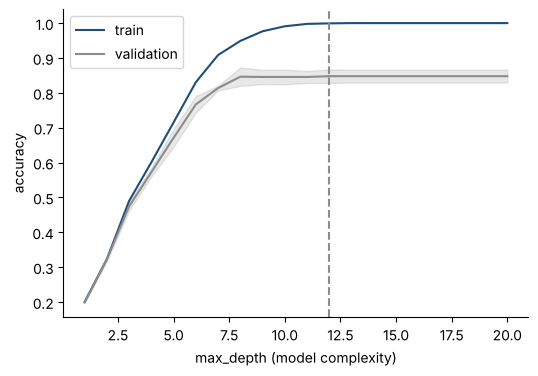

In [4]:
fig, ax = plt.subplots()
ax.plot(depths, tr_m, color=BLUE, label="train")
ax.plot(depths, va_m, color=GRAY, label="validation")
ax.fill_between(depths, va_m - va_s, va_m + va_s, color=GRAY, alpha=0.2)
ax.axvline(best_depth, color=GRAY, linestyle="--")
ax.set_xlabel("max_depth (model complexity)"); ax.set_ylabel("accuracy"); ax.legend()
plt.show()

**Giải thích từng dòng**

- `ax.fill_between(x, low, high, alpha=0.2)`: tô một dải mờ quanh đường xám để cho thấy độ dao động giữa các phần (± một độ lệch chuẩn).
- `ax.axvline(best_depth, ...)`: vạch đứng ở độ sâu tốt nhất.

**Cách đọc.**
- **Con số:** điểm xác nhận cao nhất **84,8%** ở độ sâu **12**. Ở độ sâu 20, điểm phần học là **100,0%** còn phần xác nhận **84,8%**.
- **Bức tranh:** bên trái (cây nông) cả hai đường đều thấp: Tí **học chưa đủ**. Đi sang phải đường xanh leo tới 100% còn đường xám đi ngang hoặc chùng: Tí **học vẹt**. Chỗ đường xám cao nhất là độ phức tạp vừa.
- **Lưu ý:** dải mờ cho thấy nhiều độ sâu gần đỉnh **không khác nhau rõ rệt**. Chọn độ sâu **nhỏ nhất** nằm trong dải đó (đơn giản hơn).
- **Câu hỏi tiếp:** biết độ phức tạp vừa rồi, nếu vẫn chưa đủ điểm thì thêm dữ liệu có giúp không?

**Mang về chặng 1:** đường cong xác nhận chỉ ra độ phức tạp vừa; chọn mô hình đơn giản nhất còn nằm trong dải sai số của đỉnh.

## Chặng 2: Đường cong học, thêm dữ liệu có giúp không?

**Câu hỏi:** nếu cho mô hình **nhiều ca hơn**, điểm đề mới có lên không?

Đời thường: học trò học 20% đề, 40%, ... 100% đề, rồi thi. Nếu điểm thi vẫn đang leo khi hết đề, thêm đề có ích. Nếu đã đi ngang, thêm đề vô ích. Hàm `learning_curve` làm đúng việc đó: cho mô hình học trên các phần dữ liệu tăng dần.

In [5]:
from sklearn.model_selection import learning_curve
sizes = np.linspace(0.1, 1.0, 8)
n_tr, tr_l, va_l = learning_curve(DecisionTreeClassifier(max_depth=best_depth, random_state=0), X_train, y_train,
                                  train_sizes=sizes, cv=cv, shuffle=True, random_state=0)
print("train sizes:", n_tr.tolist())
print("validation score at each size:", va_l.mean(axis=1).round(3).tolist())

train sizes: [107, 246, 384, 523, 661, 800, 938, 1077]
validation score at each size: [0.637, 0.731, 0.794, 0.82, 0.828, 0.833, 0.848, 0.848]


**Giải thích từng dòng**

- `learning_curve(model, X, y, train_sizes=..., cv=cv)`: với mỗi cỡ dữ liệu học, chạy kiểm định chéo; trả về các cỡ thật (số ca), bảng điểm phần học và bảng điểm phần xác nhận.
- `train_sizes=np.linspace(0.1, 1.0, 8)`: 8 mốc từ 10% đến 100% của phần học. `linspace` chia đều đoạn từ 0,1 đến 1,0.
- `shuffle=True, random_state=0`: xáo trước khi lấy phần đầu, để các mốc nhỏ không toàn một chữ số.

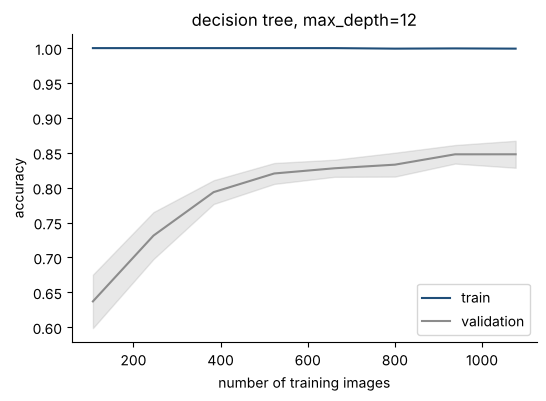

In [6]:
def plot_learning(n, tr, va, title):
    fig, ax = plt.subplots()
    ax.plot(n, tr.mean(axis=1), color=BLUE, label="train")
    ax.plot(n, va.mean(axis=1), color=GRAY, label="validation")
    ax.fill_between(n, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=GRAY, alpha=0.2)
    ax.set_xlabel("number of training images"); ax.set_ylabel("accuracy"); ax.set_title(title); ax.legend()
    plt.show()
plot_learning(n_tr, tr_l, va_l, f"decision tree, max_depth={best_depth}")

**Giải thích từng dòng**

- `def plot_learning(n, tr, va, title):`: gói đoạn vẽ vào một hàm để dùng lại, chỉ đổi dữ liệu và tiêu đề. `def` là cách đặt tên cho một khối lệnh.

**Cách đọc.**
- **Con số:** điểm xác nhận đi từ **63,7%** (ít dữ liệu nhất) lên **84,8%** (nhiều nhất). Điểm phần học cuối cùng: **99,9%**.
- **Bức tranh:** nếu đường xám vẫn còn dốc lên ở bên phải, **thêm dữ liệu sẽ giúp**. Nếu đã phẳng thì thêm dữ liệu cùng loại gần như vô ích. Khoảng cách giữa hai đường là mức học vẹt còn lại.
- **Câu hỏi tiếp:** mô hình khác thì hình dạng đường cong khác ra sao?

**Mang về chặng 2:** đường cong học trả lời "thêm dữ liệu có đáng tiền không" trước khi bỏ tiền ra thu thập.

## Chặng 3: Hai bệnh, hai thuốc

**Câu hỏi:** học vẹt và học chưa đủ trông khác nhau thế nào trên đường cong học?

Ta vẽ hai mô hình trên cùng dữ liệu:

- **Cây sâu 3 tầng** (quá đơn giản cho bài toán 10 chữ số) có thể học chưa đủ.
- **Cây không giới hạn** nhớ từng ảnh nên có thể học vẹt.

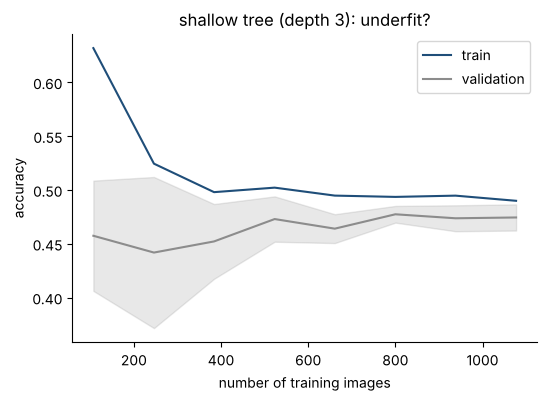

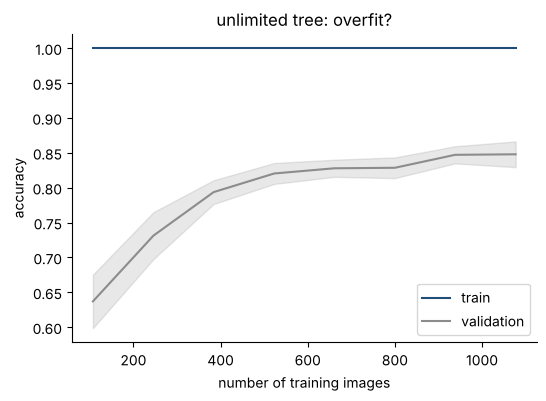

In [7]:
simple = learning_curve(DecisionTreeClassifier(max_depth=3, random_state=0), X_train, y_train, train_sizes=sizes, cv=cv, shuffle=True, random_state=0)
deep = learning_curve(DecisionTreeClassifier(random_state=0), X_train, y_train, train_sizes=sizes, cv=cv, shuffle=True, random_state=0)
plot_learning(*simple, "shallow tree (depth 3): underfit?")
plot_learning(*deep, "unlimited tree: overfit?")

**Giải thích từng dòng**

- `*simple`: dấu `*` mở gói ba kết quả `(n, tr, va)` thành ba tham số riêng của hàm vẽ.

**Cách đọc.**
- **Con số:** cây sâu 3: cuối đường cong, phần học **49,0%**, xác nhận **47,4%**. Cây không giới hạn: phần học **100,0%**, xác nhận **84,8%**.
- **Bức tranh (cách nhận biết):**
  - **Học chưa đủ (thiên lệch cao):** hai đường **gần nhau và đều thấp**. Mô hình quá đơn giản; thêm dữ liệu vô ích. Thuốc: mô hình mạnh hơn, thêm cột, bớt kìm hãm.
  - **Học vẹt (phương sai cao):** đường xanh **rất cao**, đường xám **thấp hơn hẳn**, khoảng cách lớn. Thuốc: thêm dữ liệu (nếu đường xám còn dốc), đơn giản hóa mô hình, tăng kìm hãm (như `max_depth` nhỏ hơn).
- **Câu hỏi tiếp:** có bệnh nào không chữa được bằng cả hai thuốc không?

**Mang về chặng 3:** hai đường gần nhau và thấp là học chưa đủ; xanh cao, xám thấp, cách xa là học vẹt. Thuốc của hai bệnh ngược nhau.

## Chặng 4: Trần của dữ liệu, khi nhãn vốn đã nhiễu

**Câu hỏi:** nếu cả hai thuốc đều thất bại, còn gì?

Đôi khi **nhãn** vốn không chắc chắn (hai bác sĩ đọc cùng một ảnh có thể ghi khác nhau). Khi đó có một **trần** điểm mà không mô hình nào vượt được. Ta mô phỏng: làm sai ngẫu nhiên **20% nhãn** trong dữ liệu (dựng có chủ đích) rồi xem đường cong học của một mô hình tốt (hồi quy logistic).

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
rng = np.random.RandomState(0)
y_noisy = y_train.copy()
flip = rng.rand(len(y_noisy)) < 0.20
y_noisy[flip] = rng.randint(0, 10, size=flip.sum())
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
clean = learning_curve(logit, X_train, y_train, train_sizes=sizes, cv=cv, shuffle=True, random_state=0)
noisy = learning_curve(logit, X_train, y_noisy, train_sizes=sizes, cv=cv, shuffle=True, random_state=0)
print("share of labels changed:", round(float(flip.mean()), 3))
print("final validation score, clean labels:", round(clean[2].mean(axis=1)[-1], 3), "| noisy labels:", round(noisy[2].mean(axis=1)[-1], 3))

share of labels changed: 0.203
final validation score, clean labels: 0.964 | noisy labels: 0.729


**Giải thích từng dòng**

- `y_train.copy()`: sao chép nhãn trước khi làm hỏng để không đổi bản gốc.
- `rng.rand(len(y_noisy)) < 0.20`: mỗi ảnh bốc một số ngẫu nhiên từ 0 đến 1; số nhỏ hơn 0,2 thì ảnh đó bị chọn làm sai nhãn (khoảng 20% ảnh).
- `y_noisy[flip] = rng.randint(0, 10, size=flip.sum())`: thay nhãn của các ảnh đã chọn bằng chữ số ngẫu nhiên (có thể trùng nhãn cũ, nên tỉ lệ nhãn thật sự đổi hơi thấp hơn 20%).

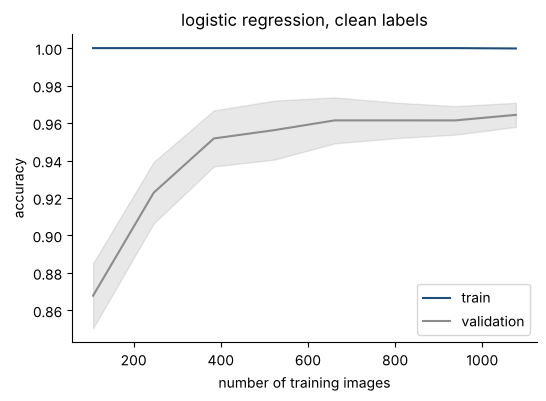

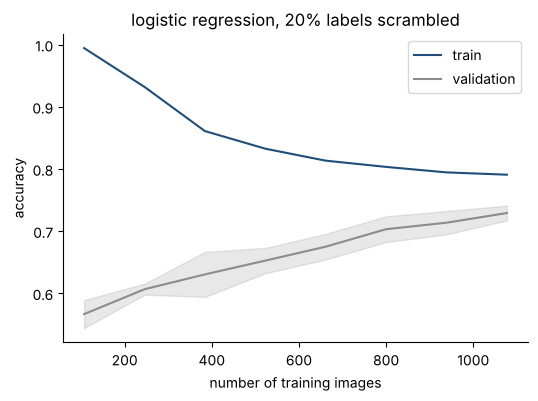

In [9]:
plot_learning(*clean, "logistic regression, clean labels")
plot_learning(*noisy, "logistic regression, 20% labels scrambled")

**Giải thích từng dòng**

**Cách đọc.**
- **Con số:** điểm xác nhận cuối: nhãn sạch **96,4%**, nhãn nhiễu **72,9%**. (Lưu ý: ở nhãn nhiễu, phần xác nhận cũng bị chấm trên nhãn nhiễu nên điểm thấp hơn trần thật.)
- **Bức tranh:** khi nhãn nhiễu, hai đường **chững lại ở mức thấp hơn** dù mô hình tốt và dữ liệu nhiều. Thêm ca cùng loại không cứu được. Việc cần làm là **sửa quy trình gán nhãn** (hướng dẫn rõ hơn, hai người cùng gán rồi đối chiếu), không phải đổi mô hình.
- **Bài học nghề:** trước khi tốn tiền cho mô hình lớn, hỏi: *"nhãn đáng tin đến đâu?"* và *"hai người gán nhãn đồng ý với nhau bao nhiêu phần trăm?"*.

**Mang về chặng 4:** có một trần do chất lượng nhãn; khi đường cong chững thấp, hãy nhìn lại dữ liệu trước khi nhìn lại mô hình.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Khoảng cách bài cũ và đề mới là triệu chứng, chưa phải chẩn đoán. |
| 1 | Đường cong xác nhận chọn độ phức tạp vừa; ưu tiên mô hình đơn giản nhất còn trong dải sai số của đỉnh. |
| 2 | Đường cong học cho biết thêm dữ liệu có đáng tiền không. |
| 3 | Hai đường gần nhau và thấp: học chưa đủ. Xanh cao, xám thấp: học vẹt. Thuốc ngược nhau. |
| 4 | Nhãn nhiễu tạo ra trần điểm; sửa dữ liệu trước khi sửa mô hình. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Học chưa đủ | thiên lệch cao (high bias, underfit) | hai đường thấp và gần nhau |
| Học vẹt | phương sai cao (high variance, overfit) | khoảng cách train và validation |
| Điểm theo độ phức tạp | đường cong xác nhận | `validation_curve` |
| Điểm theo lượng dữ liệu | đường cong học | `learning_curve` |
| Núm chống học vẹt | tham số kìm hãm | `max_depth` |
| Trần do nhãn sai | nhiễu nhãn | `y_noisy` |

**Thử thách tự làm**

1. Chạy `validation_curve` cho `KNeighborsClassifier` với `n_neighbors` từ 1 đến 30 (nhớ chuẩn hóa nếu cần). Đỉnh nằm ở đâu? k = 1 nằm bên nào của đường cong?
2. Vẽ đường cong học cho `SVC()` mặc định trên chữ số. Nó thuộc hình dạng nào trong chặng 3?
3. Thêm `n_jobs=-1` vào `learning_curve` và so thời gian chạy. Khi nào cách này đáng làm?
4. Ở chặng 4, đổi tỉ lệ nhiễu từ 20% thành 5% và 40%. Trần điểm dịch chuyển thế nào?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Đọc được đường cong xác nhận và chọn độ phức tạp vừa.
- [ ] Đọc được đường cong học và trả lời có nên thêm dữ liệu không.
- [ ] Phân biệt học vẹt và học chưa đủ bằng hình dạng hai đường.
- [ ] Nói được thuốc tương ứng cho mỗi bệnh.
- [ ] Nhận ra dấu hiệu của trần do nhãn nhiễu.

## Phần thưởng (Tip pro): Dải sai số và quy tắc một sai số chuẩn


Trong đường cong xác nhận, nếu nhiều giá trị của tham số cho điểm gần đỉnh (nằm trong **một sai số chuẩn** của đỉnh), hãy chọn giá trị cho mô hình **đơn giản nhất** trong số đó. Sai số chuẩn là `std / sqrt(số phần)`. Cách này đã dùng ở C9, giờ bạn có thể áp dụng ngay cho bất kỳ tham số nào của `validation_curve`.